# Task 3 — Portfolio Construction & Performance
### QFI Internship · Market Risk Project · Phase 3
**Prepared by:** Arham Shah

---

**Objective.** Turn the clean data into a real, invested portfolio: track its dollar value, daily P&L and returns under realistic rebalancing and trading costs, and measure risk-adjusted performance against the S&P 500.

**What this notebook delivers**
- A **holdings-based backtest engine** (dollar positions drift with prices; rebalancing on the true last trading day of each period)
- **Transaction costs and turnover** included
- A comparison of **Buy & Hold vs. Monthly vs. Quarterly** rebalancing
- A full metrics table: CAGR, volatility, Sharpe, Sortino, max drawdown, Calmar, beta, alpha, tracking error, information ratio
- Charts: value, drawdown with the worst episodes, daily P&L, return distribution, weight drift and a monthly return heatmap
- **P&L attribution** by stock

> **Pipeline:** Task 1 (Collection) → Task 2 (Cleaning) → **Task 3 (Construction)** → VaR / Backtesting

> **How to run:** open in Google Colab → *Runtime → Run all*. The notebook downloads anything it needs, so it also works if run on its own.

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings('ignore')

try:
    import yfinance as yf
except ImportError:            # Colab usually has it; install if missing
    %pip install -q yfinance
    import yfinance as yf

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

plt.rcParams.update({
    'figure.figsize': (12, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


In [2]:
# ---- Project configuration (single source of truth) ----------------------
UNIVERSE = {                     # ticker : GICS-style sector
    'AAPL' : 'Information Technology',
    'MSFT' : 'Information Technology',
    'NVDA' : 'Information Technology',
    'GOOGL': 'Communication Services',
    'META' : 'Communication Services',
    'AMZN' : 'Consumer Discretionary',
    'TSLA' : 'Consumer Discretionary',
    'JPM'  : 'Financials',
    'XOM'  : 'Energy',
    'UNH'  : 'Health Care',
}
TICKERS    = list(UNIVERSE)
BENCHMARK  = '^GSPC'             # S&P 500
START_DATE = '2020-07-24'
END_DATE   = '2026-07-25'        # yfinance end date is exclusive
TRADING_DAYS = 252

RAW_PRICE_FILE  = 'Raw_Portfolio_Price.csv'
RAW_VOLUME_FILE = 'Raw_Portfolio_Volume.csv'
BENCH_FILE      = 'Benchmark_prices.csv'

print(f'{len(TICKERS)} stocks across {len(set(UNIVERSE.values()))} sectors | '
      f'benchmark {BENCHMARK} | {START_DATE} -> {END_DATE}')

# ---- Portfolio inputs ----
INITIAL_VALUE  = 1_000_000      # USD
REBALANCE      = 'M'            # 'M' monthly, 'Q' quarterly, 'W' weekly, None = buy & hold
COST_BPS       = 5              # one-way trading cost in basis points
RISK_FREE_RATE = 0.0            # annual; set e.g. 0.04 for a 4% T-bill rate
TARGET_WEIGHTS = pd.Series(1 / len(TICKERS), index=TICKERS)   # equal weight
assert abs(TARGET_WEIGHTS.sum() - 1) < 1e-9
print(f'Initial value ${INITIAL_VALUE:,.0f} | rebalance {REBALANCE} | cost {COST_BPS} bps | '
      f'weights {TARGET_WEIGHTS.iloc[0]:.1%} each')

10 stocks across 6 sectors | benchmark ^GSPC | 2020-07-24 -> 2026-07-25
Initial value $1,000,000 | rebalance M | cost 5 bps | weights 10.0% each


## 1. Load clean data from Task 2
If Task 2's output isn't in this session, the raw prices are loaded or downloaded and lightly cleaned instead.

In [3]:
# ---- Robust Yahoo Finance downloader (retries + clear errors) ------------
def download_yahoo(symbols, start, end, retries=3, pause=2):
    """Return (adj_close, volume) DataFrames for `symbols`."""
    symbols = [symbols] if isinstance(symbols, str) else list(symbols)
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            raw = yf.download(symbols, start=start, end=end, auto_adjust=False,
                              progress=False, threads=True, group_by='column')
            adj, vol = raw['Adj Close'], raw['Volume']
            if isinstance(adj, pd.Series):
                adj, vol = adj.to_frame(symbols[0]), vol.to_frame(symbols[0])
            adj, vol = adj[symbols].dropna(how='all'), vol[symbols].reindex(adj.dropna(how='all').index)
            if not adj.empty:
                return adj, vol
            last_err = 'empty response'
        except Exception as e:
            last_err = e
        print(f'  attempt {attempt}/{retries} failed ({last_err}); retrying...')
        time.sleep(pause * attempt)
    raise RuntimeError(f'Yahoo download failed for {symbols}: {last_err}')

In [4]:
if os.path.exists('Clean_Price_Matrix.csv'):
    prices = pd.read_csv('Clean_Price_Matrix.csv', index_col=0, parse_dates=True)
    benchmark = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True).iloc[:, 0] if os.path.exists(BENCH_FILE) \
                else download_yahoo(BENCHMARK, START_DATE, END_DATE)[0].iloc[:, 0]
    print('Loaded Clean_Price_Matrix.csv from Task 2.')
else:
    # ---- Load Task 1 output, or rebuild it if this runs in a fresh session -----
    if os.path.exists(RAW_PRICE_FILE) and os.path.exists(BENCH_FILE):
        prices_raw = pd.read_csv(RAW_PRICE_FILE, index_col=0, parse_dates=True)
        benchmark  = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True).iloc[:, 0]
        source = 'Task 1 CSV files'
    else:
        prices_raw, _ = download_yahoo(TICKERS, START_DATE, END_DATE)
        bench_df, _   = download_yahoo(BENCHMARK, START_DATE, END_DATE)
        benchmark     = bench_df.iloc[:, 0]
        prices_raw.to_csv(RAW_PRICE_FILE); benchmark.to_frame('S&P 500').to_csv(BENCH_FILE)
        source = 'fresh Yahoo Finance download (Task 1 files not found)'
    
    prices_raw.index.name = benchmark.index.name = 'Date'
    benchmark.name = 'S&P 500'
    prices_raw = prices_raw[TICKERS]
    print(f'Source: {source}')
    print(f'Prices: {prices_raw.shape[0]} rows x {prices_raw.shape[1]} stocks | benchmark: {len(benchmark)} rows')
    prices = prices_raw.reindex(benchmark.index).ffill(limit=3).dropna()
    print('Task 2 output not found - rebuilt a clean price matrix from raw data.')

prices = prices[TICKERS]
benchmark = benchmark.reindex(prices.index).ffill()
benchmark.name = 'S&P 500'
print(f'{len(prices)} trading days x {prices.shape[1]} stocks | {prices.index[0].date()} -> {prices.index[-1].date()}')

Loaded Clean_Price_Matrix.csv from Task 2.
1507 trading days x 10 stocks | 2020-07-24 -> 2026-07-24


## 2. The backtest engine
This is a **holdings-based** engine, which is how a real portfolio behaves:
1. On day 0, buy target weights of the initial capital and pay trading costs.
2. Each day, every dollar position grows with its own **simple** return, so weights drift.
3. On the **last actual trading day** of each period, trade back to target weights. Turnover is recorded and costs are deducted.

This fixes two subtle problems in a typical first draft. First, compounding log returns with `(1+r).cumprod()` is wrong, because log returns compound with `exp(cumsum)`. Second, using calendar month-ends as rebalance dates means rebalancing silently doesn't happen whenever a month ends on a weekend.

In [5]:
def rebalance_dates(index, freq):
    """Last trading day of each period (never a weekend/holiday)."""
    if freq is None:
        return set()
    s = pd.Series(index, index=index)
    return set(s.groupby(index.to_period(freq)).max()) - {index[-1]}   # no trade on the final day

def run_backtest(prices, target_w, initial_value=1_000_000, freq='M', cost_bps=0.0):
    rets = prices.pct_change().iloc[1:]
    w = target_w.reindex(prices.columns).values
    rb = rebalance_dates(rets.index, freq)
    c = cost_bps / 1e4

    # day 0: invest, paying cost on the initial purchase
    v0 = initial_value / (1 + c)
    holdings = v0 * w
    rec = [{'Date': prices.index[0], 'Value': holdings.sum(), 'Turnover': 1.0, 'Cost': initial_value - v0,
            **dict(zip(prices.columns, w))}]
    for d, r in zip(rets.index, rets.values):
        holdings = holdings * (1 + r)
        V = holdings.sum()
        turnover = cost = 0.0
        if d in rb:
            target = V * w
            traded = np.abs(target - holdings).sum()
            cost = traded * c
            V -= cost
            holdings = V * w
            turnover = traded / (V + cost)
        rec.append({'Date': d, 'Value': V, 'Turnover': turnover, 'Cost': cost,
                    **dict(zip(prices.columns, holdings / V))})
    out = pd.DataFrame(rec).set_index('Date')
    out['Return'] = out['Value'].pct_change()
    out['PnL'] = out['Value'].diff()
    out.loc[out.index[0], ['Return', 'PnL']] = [out['Value'].iloc[0] / initial_value - 1,
                                                 out['Value'].iloc[0] - initial_value]
    out['LogReturn'] = np.log1p(out['Return'])
    return out

port = run_backtest(prices, TARGET_WEIGHTS, INITIAL_VALUE, REBALANCE, COST_BPS)
print(f'Rebalances executed: {(port["Turnover"].iloc[1:] > 0).sum()}  |  '
      f'total trading costs: ${port["Cost"].sum():,.0f}')
port[['Value', 'PnL', 'Return', 'Turnover', 'Cost']].head()

Rebalances executed: 72  |  total trading costs: $5,972


,Value,PnL,Return,Turnover,Cost
Date,,,,,
2020-07-24,"999,500.2499",-499.7501,-0.0005,1.0000,499.7501
2020-07-27,"1,017,503.2669","18,003.0171",0.0180,0.0000,0.0000
2020-07-28,"1,003,119.1086","-14,384.1583",-0.0141,0.0000,0.0000
2020-07-29,"1,019,647.8307","16,528.7221",0.0165,0.0000,0.0000
2020-07-30,"1,015,406.2103","-4,241.6204",-0.0042,0.0000,0.0000


In [6]:
# Sanity check: with no rebalancing and no costs, the engine must equal the
# closed-form buy & hold value  V_T = V_0 * sum_i w_i * P_i,T / P_i,0
bh = run_backtest(prices, TARGET_WEIGHTS, INITIAL_VALUE, None, 0)
closed_form = INITIAL_VALUE * (prices.iloc[-1] / prices.iloc[0] * TARGET_WEIGHTS).sum()
print(f'Engine: {bh["Value"].iloc[-1]:,.2f}  |  closed form: {closed_form:,.2f}  |  '
      f'match: {np.isclose(bh["Value"].iloc[-1], closed_form)}')

Engine: 4,824,688.92  |  closed form: 4,824,688.92  |  match: True


## 3. Strategy comparison
The same stocks with different rebalancing rules, all net of costs, compared with simply holding the S&P 500.

In [7]:
strategies = {
    'Buy & Hold':        run_backtest(prices, TARGET_WEIGHTS, INITIAL_VALUE, None, COST_BPS),
    'Monthly rebalance': run_backtest(prices, TARGET_WEIGHTS, INITIAL_VALUE, 'M', COST_BPS),
    'Quarterly rebalance': run_backtest(prices, TARGET_WEIGHTS, INITIAL_VALUE, 'Q', COST_BPS),
}
bench_value = INITIAL_VALUE * benchmark / benchmark.iloc[0]
bench_ret = bench_value.pct_change()

def max_drawdown(v):
    dd = v / v.cummax() - 1
    return dd.min()

def metrics(value, ret, bench_ret, cost=None, turnover=None):
    ret = ret.iloc[1:]
    b = bench_ret.reindex(ret.index)
    yrs = (value.index[-1] - value.index[0]).days / 365.25
    rf_d = (1 + RISK_FREE_RATE) ** (1 / TRADING_DAYS) - 1
    ex = ret - rf_d
    downside = np.sqrt((np.minimum(ex, 0) ** 2).mean()) * np.sqrt(TRADING_DAYS)
    cagr = (value.iloc[-1] / INITIAL_VALUE) ** (1 / yrs) - 1
    vol = ret.std() * np.sqrt(TRADING_DAYS)
    mdd = max_drawdown(value)
    beta = ret.cov(b) / b.var()
    alpha = (ret.mean() - rf_d - beta * (b.mean() - rf_d)) * TRADING_DAYS
    active = ret - b
    te = active.std() * np.sqrt(TRADING_DAYS)
    m = {
        'Final value ($)': value.iloc[-1], 'Total return': value.iloc[-1] / INITIAL_VALUE - 1,
        'CAGR': cagr, 'Ann. volatility': vol,
        'Sharpe': ex.mean() / ret.std() * np.sqrt(TRADING_DAYS),
        'Sortino': ex.mean() * TRADING_DAYS / downside,
        'Max drawdown': mdd, 'Calmar': cagr / abs(mdd),
        'Beta vs S&P': beta, 'Alpha (ann.)': alpha,
        'Tracking error': te, 'Information ratio': active.mean() * TRADING_DAYS / te if te > 0 else np.nan,
        'Best day': ret.max(), 'Worst day': ret.min(), '% up days': (ret > 0).mean(),
        'Avg annual turnover': turnover.iloc[1:].sum() / yrs if turnover is not None else 0,
        'Total costs ($)': cost.sum() if cost is not None else 0,
    }
    return pd.Series(m)

table = pd.DataFrame({k: metrics(v['Value'], v['Return'], bench_ret, v['Cost'], v['Turnover'])
                      for k, v in strategies.items()})
table['S&P 500'] = metrics(bench_value, bench_ret.fillna(0), bench_ret)
pct = ['Total return', 'CAGR', 'Ann. volatility', 'Max drawdown', 'Alpha (ann.)', 'Tracking error',
       'Best day', 'Worst day', '% up days', 'Avg annual turnover']
fmt = table.copy().astype(object)
for r in table.index:
    fmt.loc[r] = [f'{x:.2%}' if r in pct else (f'${x:,.0f}' if '$' in r else f'{x:.2f}') for x in table.loc[r]]
fmt

,Buy & Hold,Monthly rebalance,Quarterly rebalance,S&P 500
Final value ($),"$4,822,278","$4,520,228","$4,708,047","$2,304,985"
Total return,382.23%,352.02%,370.80%,130.50%
CAGR,29.99%,28.59%,29.47%,14.94%
Ann. volatility,25.85%,22.97%,22.98%,16.69%
Sharpe,1.15,1.21,1.24,0.92
Sortino,1.67,1.78,1.82,1.33
Max drawdown,-34.45%,-32.83%,-31.87%,-25.43%
Calmar,0.87,0.87,0.92,0.59
Beta vs S&P,1.37,1.27,1.26,1.00
Alpha (ann.),8.59%,8.44%,9.19%,0.00%


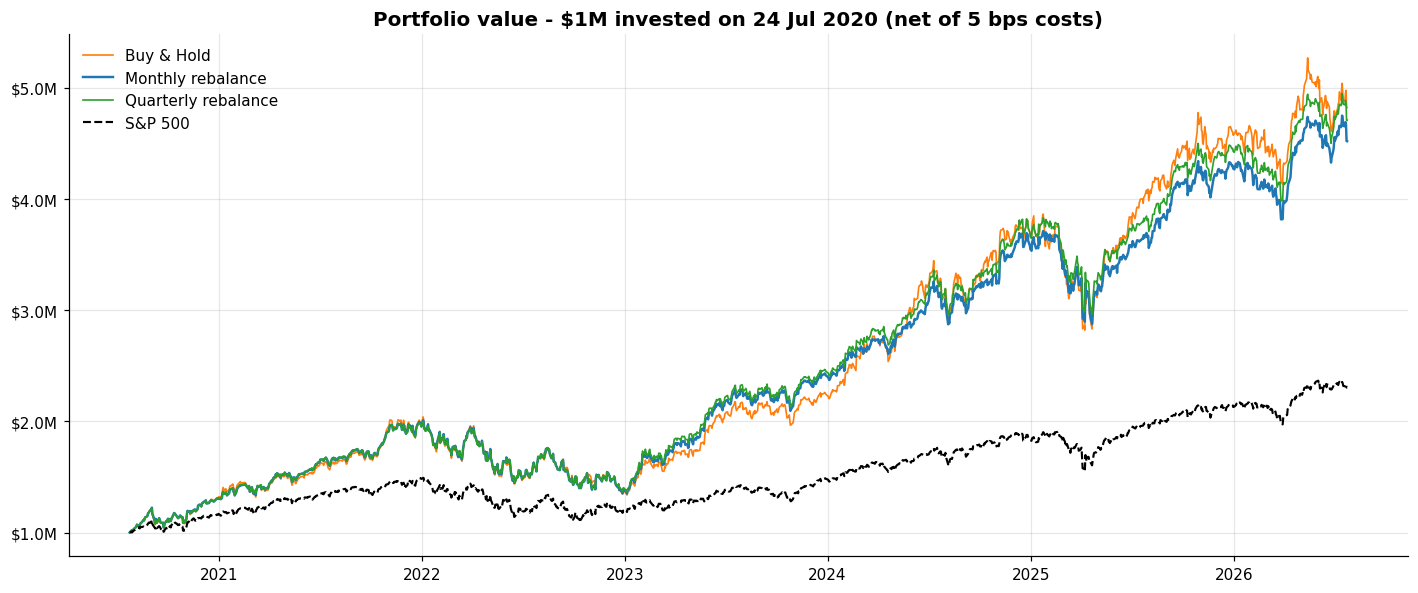

In [8]:
fig, ax = plt.subplots(figsize=(13, 5.5))
for (name, df), c in zip(strategies.items(), ['tab:orange', 'tab:blue', 'tab:green']):
    ax.plot(df['Value'], lw=1.6 if 'Monthly' in name else 1.1, color=c, label=name)
ax.plot(bench_value, color='black', lw=1.4, ls='--', label='S&P 500')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax.set_title(f'Portfolio value - ${INITIAL_VALUE/1e6:.0f}M invested on {prices.index[0]:%d %b %Y} (net of {COST_BPS} bps costs)')
ax.legend(); plt.tight_layout(); plt.show()

## 4. Deep dive: the chosen portfolio (`REBALANCE = 'M'`)
### 4a. Drawdowns and the worst episodes
Drawdown is the percentage below the previous peak. For a risk manager the depth matters, and so does **how long recovery takes**.

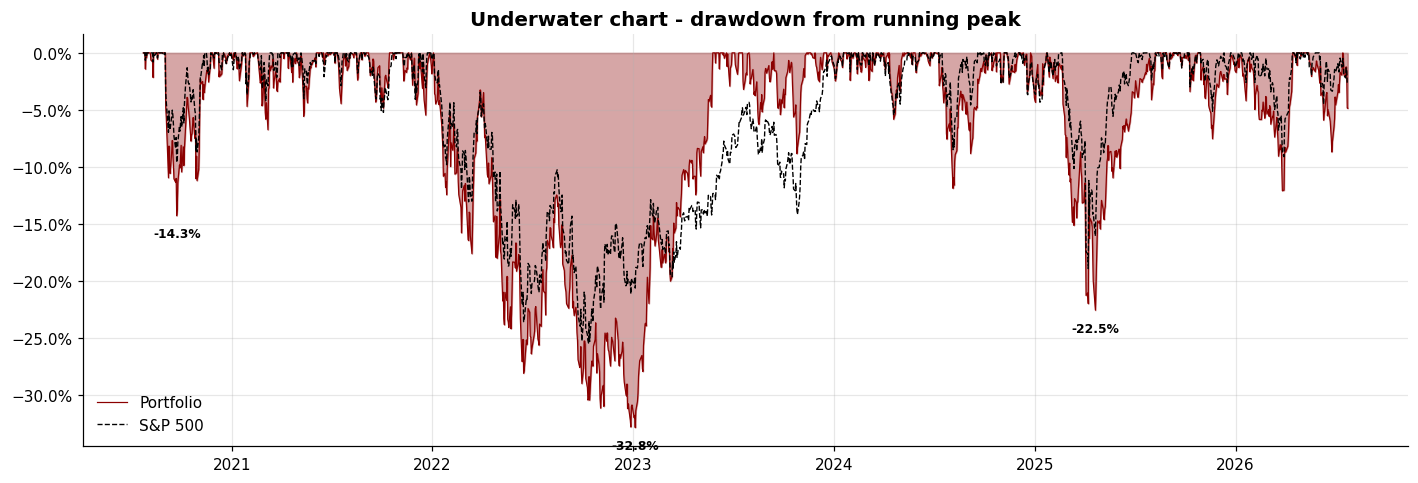

,Peak,Trough,Recovered,Depth,Peak->trough (days),Total length (days)
0,2022-01-03,2023-01-05,2023-05-26,-32.8%,263,364
1,2025-01-23,2025-04-21,2025-08-11,-22.5%,62,142
2,2020-09-02,2020-09-23,2020-11-24,-14.3%,15,59
3,2025-10-29,2026-03-27,2026-04-15,-12.1%,107,120
4,2024-07-10,2024-08-05,2024-10-14,-11.9%,18,68


In [9]:
value = port['Value']
dd = value / value.cummax() - 1

def drawdown_episodes(value, top=5):
    dd = value / value.cummax() - 1
    under = dd < 0
    eps, start = [], None
    for d, u in under.items():
        if u and start is None: start = d
        if not u and start is not None:
            eps.append((start, d)); start = None
    if start is not None: eps.append((start, None))
    rows = []
    for s, e in eps:
        seg = dd[s:e] if e is not None else dd[s:]
        trough = seg.idxmin()
        peak = value[:s].index[-2] if len(value[:s]) > 1 else s
        rows.append({'Peak': peak.date(), 'Trough': trough.date(),
                     'Recovered': e.date() if e is not None else 'not yet',
                     'Depth': seg.min(),
                     'Peak->trough (days)': np.busday_count(peak.date(), trough.date()),
                     'Total length (days)': np.busday_count(peak.date(), (e or value.index[-1]).date())})
    return pd.DataFrame(rows).sort_values('Depth').head(top).reset_index(drop=True)

episodes = drawdown_episodes(value)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(dd.index, dd, 0, color='darkred', alpha=0.35)
ax.plot(dd, color='darkred', lw=0.8, label='Portfolio')
ax.plot(bench_value / bench_value.cummax() - 1, color='black', lw=0.9, ls='--', label='S&P 500')
for _, r in episodes.head(3).iterrows():
    ax.annotate(f'{r.Depth:.1%}', (pd.Timestamp(r.Trough), r.Depth), xytext=(0, -14),
                textcoords='offset points', ha='center', fontsize=8, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(loc='lower left')
ax.set_title('Underwater chart - drawdown from running peak'); plt.tight_layout(); plt.show()
episodes.style.format({'Depth': '{:.1%}'})

### 4b. Daily P&L in dollars
The dashed lines mark the 1st and 99th percentiles. The 1st percentile is a first look at a 1-day 99% historical VaR, which the next phase models properly.

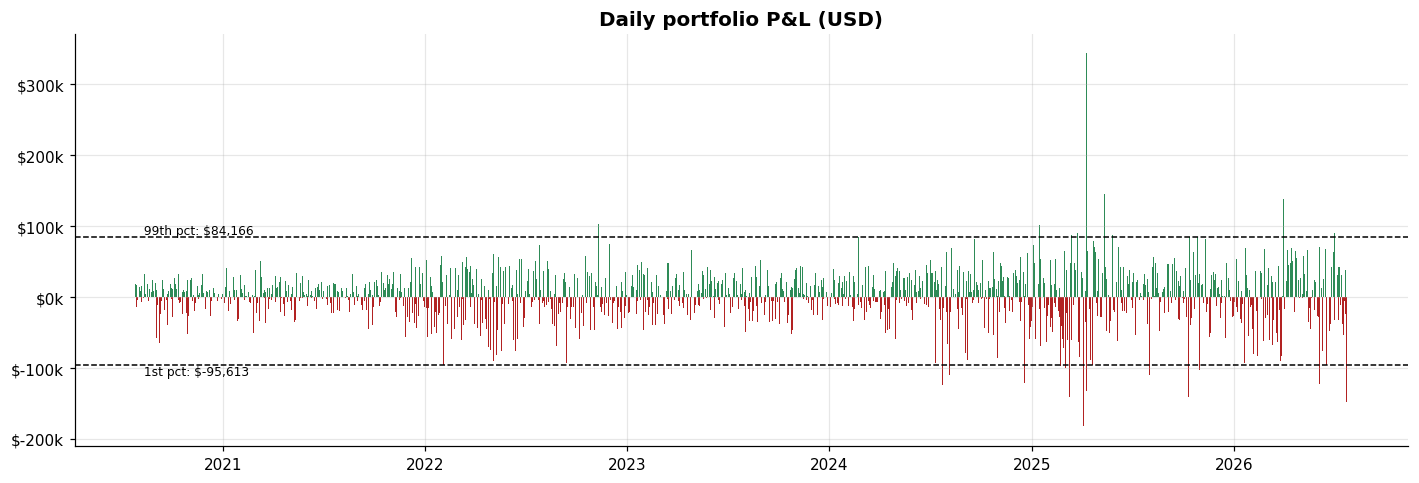

Five worst days:


,P&L ($),Return,S&P 500
Date,,,
2025-04-03 00:00:00,"$-183,962",-5.59%,-4.84%
2025-04-04 00:00:00,"$-182,173",-5.87%,-5.97%
2026-07-23 00:00:00,"$-148,266",-3.18%,-1.21%
2025-03-10 00:00:00,"$-141,329",-4.28%,-2.70%
2025-10-10 00:00:00,"$-140,507",-3.37%,-2.71%


In [10]:
pnl = port['PnL'].iloc[1:]
q01, q99 = pnl.quantile([0.01, 0.99])
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(pnl.index, pnl.where(pnl >= 0), color='seagreen', width=1.5)
ax.bar(pnl.index, pnl.where(pnl < 0), color='firebrick', width=1.5)
ax.axhline(q01, color='black', ls='--', lw=1); ax.axhline(q99, color='black', ls='--', lw=1)
ax.text(pnl.index[5], q01, f' 1st pct: ${q01:,.0f}', va='top', fontsize=8)
ax.text(pnl.index[5], q99, f' 99th pct: ${q99:,.0f}', va='bottom', fontsize=8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e3:,.0f}k'))
ax.set_title('Daily portfolio P&L (USD)'); plt.tight_layout(); plt.show()

worst = pnl.nsmallest(5).to_frame('P&L ($)'); worst['Return'] = port.loc[worst.index, 'Return']
worst['S&P 500'] = bench_ret.loc[worst.index]
print('Five worst days:'); display(worst.style.format({'P&L ($)': '${:,.0f}', 'Return': '{:.2%}', 'S&P 500': '{:.2%}'}))

### 4c. Return distribution with VaR / ES markers

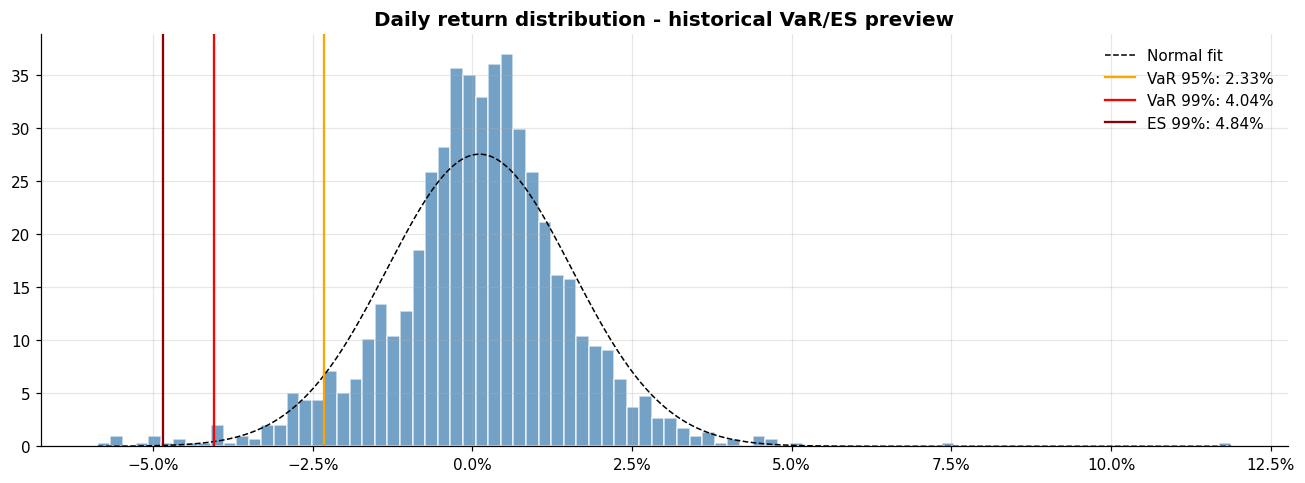

1-day 99% VaR on $4,520,228: $182,832  |  99% ES: $218,643


In [11]:
from scipy import stats
r = port['Return'].iloc[1:]
var95, var99 = -r.quantile(0.05), -r.quantile(0.01)
es99 = -r[r <= -var99].mean()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(r, bins=90, density=True, color='steelblue', alpha=0.75, edgecolor='white')
g = np.linspace(r.min(), r.max(), 400)
ax.plot(g, stats.norm.pdf(g, r.mean(), r.std()), 'k--', lw=1, label='Normal fit')
for v, lbl, c in [(var95, 'VaR 95%', 'orange'), (var99, 'VaR 99%', 'red'), (es99, 'ES 99%', 'darkred')]:
    ax.axvline(-v, color=c, lw=1.5, label=f'{lbl}: {v:.2%}')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
ax.set_title('Daily return distribution - historical VaR/ES preview'); plt.tight_layout(); plt.show()
print(f'1-day 99% VaR on ${value.iloc[-1]:,.0f}: ${var99 * value.iloc[-1]:,.0f}  |  99% ES: ${es99 * value.iloc[-1]:,.0f}')

### 4d. Weight drift: why rebalancing matters
Without rebalancing, the winners (above all NVDA) take over the portfolio, and the "diversified" equal-weight portfolio turns into a concentrated tech bet.

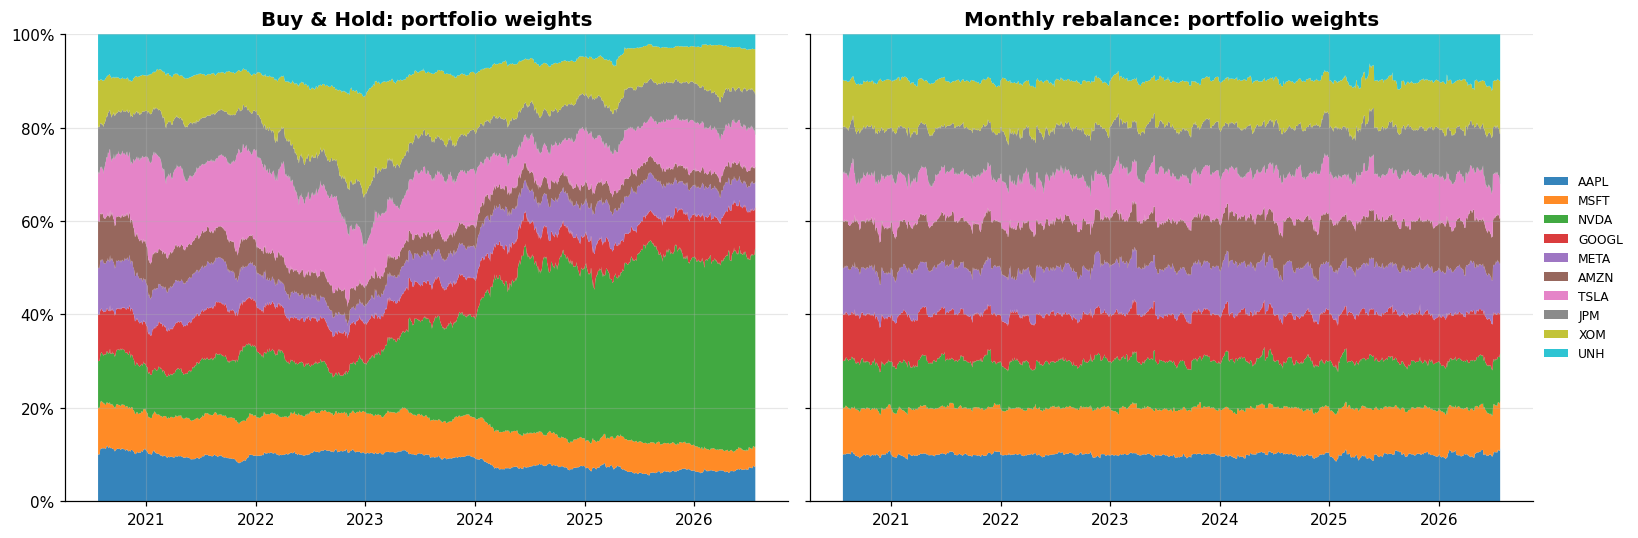

Buy & hold end weights: largest NVDA 42.2%, smallest AMZN 3.2%  (target 10%)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
cols = plt.get_cmap('tab10').colors
for ax, name in zip(axes, ['Buy & Hold', 'Monthly rebalance']):
    w = strategies[name][TICKERS]
    ax.stackplot(w.index, w.T.values, labels=TICKERS, colors=cols, alpha=0.9)
    ax.set_title(f'{name}: portfolio weights'); ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout(); plt.show()
final_bh = strategies['Buy & Hold'][TICKERS].iloc[-1].sort_values(ascending=False)
print(f'Buy & hold end weights: largest {final_bh.index[0]} {final_bh.iloc[0]:.1%}, '
      f'smallest {final_bh.index[-1]} {final_bh.iloc[-1]:.1%}  (target {1/len(TICKERS):.0%})')

### 4e. Monthly returns heatmap

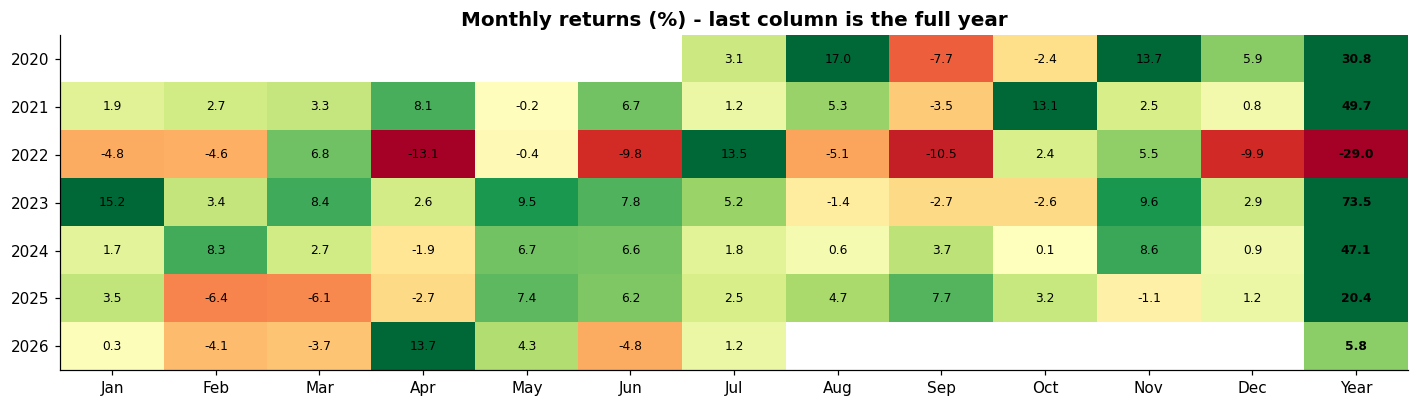

In [13]:
monthly = value.resample('ME').last().pct_change()
monthly.iloc[0] = value.resample('ME').last().iloc[0] / INITIAL_VALUE - 1
mt = monthly.to_frame('r'); mt['Y'] = mt.index.year; mt['M'] = mt.index.strftime('%b')
grid = mt.pivot(index='Y', columns='M', values='r')[['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']]
grid['Year'] = value.groupby(value.index.year).last() / pd.concat([pd.Series([INITIAL_VALUE]), value.groupby(value.index.year).last()[:-1]]).values - 1
fig, ax = plt.subplots(figsize=(13, 3.8))
d = grid.values * 100
im = ax.imshow(d, cmap='RdYlGn', vmin=-12, vmax=12, aspect='auto')
ax.set_xticks(range(13), grid.columns); ax.set_yticks(range(len(grid)), grid.index)
for i in range(d.shape[0]):
    for j in range(d.shape[1]):
        if not np.isnan(d[i, j]):
            ax.text(j, i, f'{d[i, j]:.1f}', ha='center', va='center', fontsize=8,
                    fontweight='bold' if j == 12 else 'normal')
ax.grid(False); ax.set_title('Monthly returns (%) - last column is the full year')
plt.tight_layout(); plt.show()

### 4f. P&L attribution: who made (and lost) the money?
Each stock's daily contribution is its start-of-day weight × its return × the portfolio value. Summed over the whole sample, the contributions add up to the total P&L.

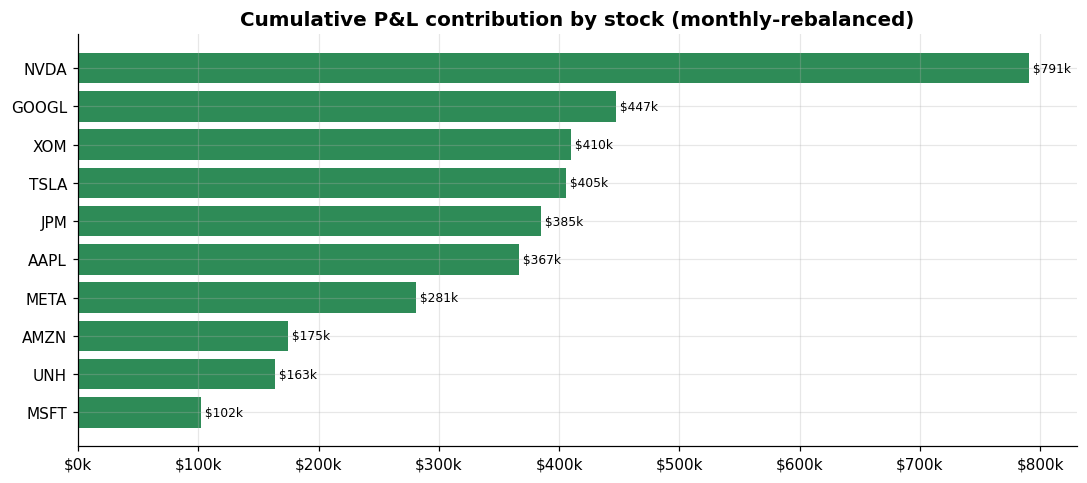

Gross stock P&L $3,526,200  -  costs $5,972  =  net P&L $3,520,228  (engine: $3,520,228)


In [14]:
rets = prices.pct_change()
w_prev = port[TICKERS].shift(1)
contrib = (w_prev * rets).mul(port['Value'].shift(1), axis=0).iloc[1:]
attr = contrib.sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(attr.index, attr.values, color=np.where(attr > 0, 'seagreen', 'firebrick'))
for i, v in enumerate(attr.values):
    ax.text(v, i, f' ${v/1e3:,.0f}k', va='center', fontsize=8)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e3:,.0f}k'))
ax.set_title('Cumulative P&L contribution by stock (monthly-rebalanced)'); plt.tight_layout(); plt.show()
gross = attr.sum(); costs = port['Cost'].sum(); net = value.iloc[-1] - INITIAL_VALUE
print(f'Gross stock P&L ${gross:,.0f}  -  costs ${costs:,.0f}  =  net P&L ${gross - costs:,.0f}  '
      f'(engine: ${net:,.0f})')

## 5. Save outputs for the VaR / backtesting phases

In [15]:
out = port[['Return', 'LogReturn', 'Value', 'PnL', 'Turnover', 'Cost']].copy()
out['Benchmark_Value'] = bench_value
out['Benchmark_Return'] = bench_ret
out['Drawdown'] = dd
out.to_csv('Portfolio_Construction.csv')
port[TICKERS].to_csv('Portfolio_Weights.csv')
table.to_csv('Strategy_Comparison.csv')
contrib.to_csv('PnL_Attribution_Daily.csv')
print('Saved: Portfolio_Construction.csv, Portfolio_Weights.csv, Strategy_Comparison.csv, PnL_Attribution_Daily.csv')
out.tail()

Saved: Portfolio_Construction.csv, Portfolio_Weights.csv, Strategy_Comparison.csv, PnL_Attribution_Daily.csv


,Return,LogReturn,Value,PnL,Turnover,Cost,Benchmark_Value,Benchmark_Return,Drawdown
Date,,,,,,,,,
2026-07-20,-0.0011,-0.0011,"4,654,205.6084","-4,912.0308",0.0000,0.0000,"2,314,719.0617",-0.0019,-0.0204
2026-07-21,0.0083,0.0082,"4,692,758.0648","38,552.4564",0.0000,0.0000,"2,335,219.0610",0.0089,-0.0122
2026-07-22,-0.0050,-0.0050,"4,669,496.9634","-23,261.1014",0.0000,0.0000,"2,332,034.5420",-0.0014,-0.0171
2026-07-23,-0.0318,-0.0323,"4,521,230.9956","-148,265.9678",0.0000,0.0000,"2,303,840.9502",-0.0121,-0.0483
2026-07-24,-0.0002,-0.0002,"4,520,227.8514","-1,003.1442",0.0000,0.0000,"2,304,985.4152",0.0005,-0.0486


In [16]:
m = table['Monthly rebalance']; b = table['S&P 500']
print('=' * 64)
print(f'  PORTFOLIO SUMMARY  |  {AUTHOR}')
print('=' * 64)
print(f'  Invested           : ${INITIAL_VALUE:,.0f} on {prices.index[0]:%d %b %Y}')
print(f'  Final value        : ${m["Final value ($)"]:,.0f} on {prices.index[-1]:%d %b %Y}')
print(f'  CAGR               : {m["CAGR"]:.2%}   (S&P 500 {b["CAGR"]:.2%})')
print(f'  Volatility         : {m["Ann. volatility"]:.2%}   (S&P 500 {b["Ann. volatility"]:.2%})')
print(f'  Sharpe / Sortino   : {m["Sharpe"]:.2f} / {m["Sortino"]:.2f}')
print(f'  Max drawdown       : {m["Max drawdown"]:.2%}   (S&P 500 {b["Max drawdown"]:.2%})')
print(f'  Beta / Alpha       : {m["Beta vs S&P"]:.2f} / {m["Alpha (ann.)"]:.2%}')
print(f'  1-day VaR99 / ES99 : {var99:.2%} / {es99:.2%}')
print('=' * 64)

  PORTFOLIO SUMMARY  |  Arham Shah
  Invested           : $1,000,000 on 24 Jul 2020
  Final value        : $4,520,228 on 24 Jul 2026
  CAGR               : 28.59%   (S&P 500 14.94%)
  Volatility         : 22.97%   (S&P 500 16.69%)
  Sharpe / Sortino   : 1.21 / 1.78
  Max drawdown       : -32.83%   (S&P 500 -25.43%)
  Beta / Alpha       : 1.27 / 8.44%
  1-day VaR99 / ES99 : 4.04% / 4.84%


## Key takeaways
- Built a **holdings-based** portfolio engine with real rebalancing dates, transaction costs and turnover, and checked it against the closed-form buy-and-hold value.
- The output is the daily **value, P&L and returns** of a $1M equal-weighted, monthly-rebalanced portfolio, alongside buy-and-hold, quarterly and the S&P 500.
- Rebalancing keeps the portfolio **diversified**. Buy-and-hold slowly turns into a concentrated bet on the biggest winners.
- Drawdown episodes, the P&L tails and a VaR/ES preview set up the next phase: **formal VaR modelling and backtesting**.

*Prepared by Arham Shah.*